# 99 — Comparaison des modèles

Rassemble tous les runs évalués (`results/*/test_output.json`) pour les comparer sur le **même** split de test.
Ce notebook se met à jour tout seul : il suffit de le relancer après chaque nouveau run.

In [1]:
import os, sys
from pathlib import Path

# Le notebook tourne depuis notebooks/ : on se place à la racine du projet
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import yaml

from src.viz import setup_style, collect_runs, read_run, plot_confusion, SERIES, INK_MUTED
import json

setup_style()
runs = collect_runs()
runs.sort_values("f1_macro", ascending=False).round(4)

,accuracy,f1_macro,recall_Cyst,recall_Normal,recall_Stone,recall_Tumor
run,,,,,,
m1-e4-residual-s42-v1,0.8122,0.7361,0.8596,0.9989,0.8622,0.2665
m1-e2-crop-s43-v1,0.7686,0.7077,0.8986,0.9072,0.7733,0.2500
m1-e1-regul-s43-v1,0.7190,0.6998,0.9630,0.7010,0.7156,0.4203
model2-v1,0.7570,0.6893,0.5302,0.9885,0.9556,0.3984
m1-e4-residual-s43-v1,0.7590,0.6862,0.6511,0.9954,0.8578,0.2830
m1-e2-crop-s42-v1,0.7058,0.6792,0.9142,0.7331,0.8311,0.2692
m1-e0-baseline-s44-v1,0.7954,0.6745,0.9727,1.0000,0.6444,0.1484
m1-e2-crop-s44-v1,0.7671,0.6716,0.8051,0.9840,0.7733,0.1896
m1-e4-residual-s44-v1,0.7306,0.6538,0.5634,0.9599,0.8622,0.3352


## Hyperparamètres de chaque run

In [2]:
cfgs = {}
for r in runs.index:
    c = yaml.safe_load((Path("results") / r / "config.yaml").read_text())
    cfgs[r] = {"model": c["model"]["name"], "img_size": c["data"]["img_size"], **c["train"],
               **{f"param_{k}": v for k, v in c["model"].get("params", {}).items()}}
pd.DataFrame(cfgs).T

,model,img_size,epochs,batch_size,lr,weight_decay,class_weights,param_dropout,label_smoothing,select_metric,patience,sampler,mixup,param_block,param_widths,param_drop2d,param_pretrained
m1-e0-baseline-s42-v1,model1,128,10,64,0.001,0.0001,True,0.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
m1-e0-baseline-s43-v1,model1,128,10,64,0.001,0.0001,True,0.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
m1-e0-baseline-s44-v1,model1,128,10,64,0.001,0.0001,True,0.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
m1-e1-regul-s42-v1,model1,128,30,64,0.001,0.0001,True,0.3,0.1,f1_macro,8,NaN,NaN,NaN,NaN,NaN,NaN
m1-e1-regul-s43-v1,model1,128,30,64,0.001,0.0001,True,0.3,0.1,f1_macro,8,NaN,NaN,NaN,NaN,NaN,NaN
m1-e1-regul-s44-v1,model1,128,30,64,0.001,0.0001,True,0.3,0.1,f1_macro,8,NaN,NaN,NaN,NaN,NaN,NaN
m1-e2-crop-s42-v1,model1,128,30,64,0.001,0.0001,True,0.3,0.1,f1_macro,8,NaN,NaN,NaN,NaN,NaN,NaN
m1-e2-crop-s43-v1,model1,128,30,64,0.001,0.0001,True,0.3,0.1,f1_macro,8,NaN,NaN,NaN,NaN,NaN,NaN
m1-e2-crop-s44-v1,model1,128,30,64,0.001,0.0001,True,0.3,0.1,f1_macro,8,NaN,NaN,NaN,NaN,NaN,NaN
m1-e3-mix-s42-v1,model1,128,30,64,0.001,0.0001,False,0.3,0.1,f1_macro,8,balanced,"{'alpha': 0.4, 'cutmix_prob': 0.5, 'prob': 0.8}",NaN,NaN,NaN,NaN


## Courbes de validation
Comme au tableau : un modèle dont la loss de validation remonte est en sur-apprentissage.

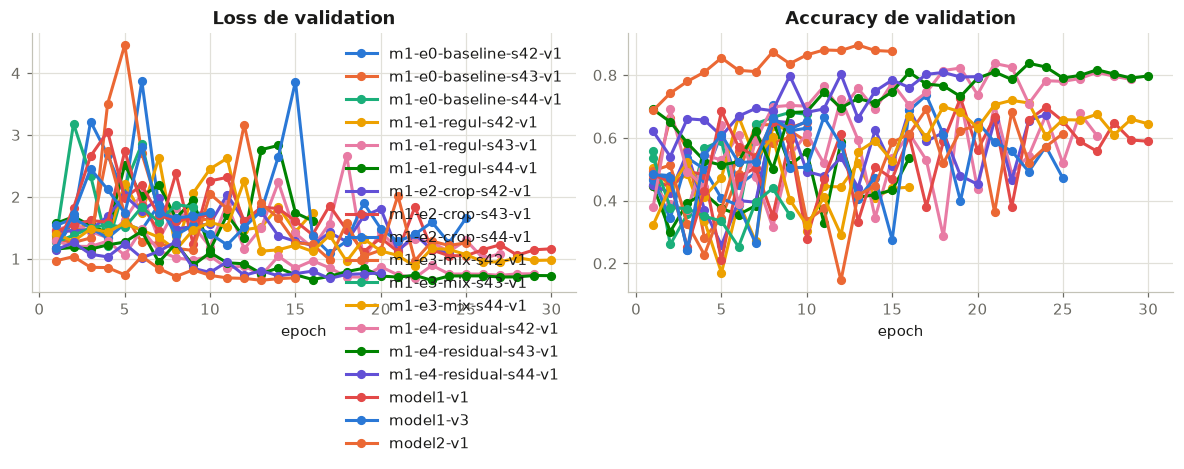

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for k, r in enumerate(runs.index):          # couleur fixe par run (ordre alphabétique)
    _, va = read_run(Path("results") / r)
    color = SERIES[k % len(SERIES)]
    axes[0].plot(va.epoch, va.loss, marker="o", color=color, label=r)
    axes[1].plot(va.epoch, va.acc, marker="o", color=color, label=r)
axes[0].set_title("Loss de validation"); axes[1].set_title("Accuracy de validation")
for ax in axes: ax.set_xlabel("epoch")
axes[0].legend()
plt.tight_layout(); plt.show()

## Métriques test

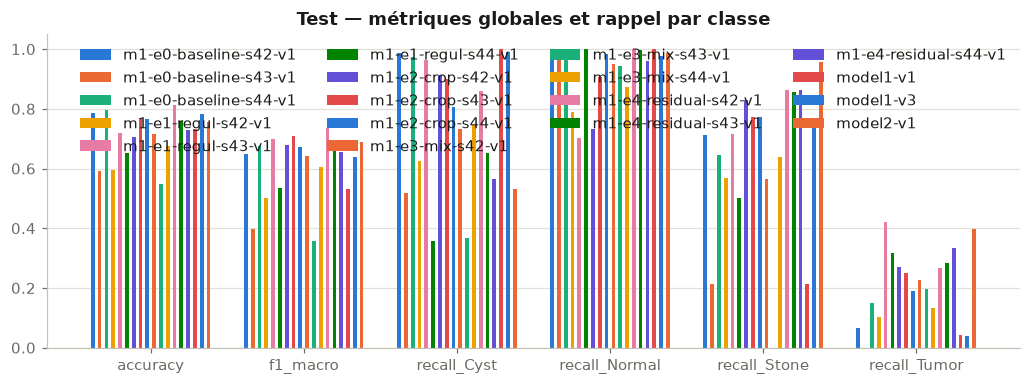

In [4]:
metrics = ["accuracy", "f1_macro"] + [c for c in runs.columns if c.startswith("recall_")]
fig, ax = plt.subplots(figsize=(10, 3.6))
w = 0.8 / max(len(runs), 1)
for k, r in enumerate(runs.index):
    x = [i + (k - (len(runs) - 1) / 2) * w for i in range(len(metrics))]
    ax.bar(x, runs.loc[r, metrics], w - 0.02, color=SERIES[k % len(SERIES)], label=r)
ax.set_xticks(range(len(metrics)), metrics); ax.set_ylim(0, 1.05); ax.legend(ncols=4)
ax.set_title("Test — métriques globales et rappel par classe"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

Meilleur run (F1 macro) : m1-e4-residual-s42-v1


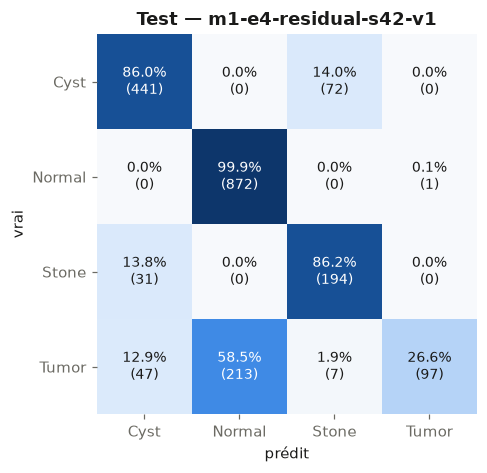

In [5]:
best = runs.f1_macro.idxmax()
o = json.loads((Path("results") / best / "test_output.json").read_text())
print(f"Meilleur run (F1 macro) : {best}")
plot_confusion(o["confusion_matrix"]["matrix"], o["confusion_matrix"]["labels"], f"Test — {best}"); plt.show()